In [ ]:
library(tidyverse)
library(ggplot2)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [ ]:
Df <- read.csv ("/content/WA_Fn-UseC_-HR-Employee-Attrition.csv")

In [ ]:
head(Df)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,⋯,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
,<int>,<chr>,<chr>,<int>,<chr>,<int>,<int>,<chr>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,⋯,1,80,0,8,0,1,6,4,0,5
2,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,⋯,4,80,1,10,3,3,10,7,1,7
3,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,⋯,2,80,0,7,3,3,0,0,0,0
4,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,⋯,3,80,0,8,3,3,8,7,3,0
5,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,⋯,4,80,1,6,3,3,2,2,2,2
6,32,No,Travel_Frequently,1005,Research & Development,2,2,Life Sciences,1,8,⋯,3,80,0,8,2,2,7,7,3,6


In [ ]:
dim(Df)

[1] 1470   35

In [ ]:
summary(Df)

      Age            Attrition      BusinessTravel   DailyRate     
 Min.   :18.00   Length   :1470   Length   :1470   Min.   : 102.0  
 1st Qu.:30.00   N.unique :   2   N.unique :   3   1st Qu.: 465.0  
 Median :36.00   N.blank  :   0   N.blank  :   0   Median : 802.0  
 Mean   :36.92   Min.nchar:   2   Min.nchar:  10   Mean   : 802.5  
 3rd Qu.:43.00   Max.nchar:   3   Max.nchar:  17   3rd Qu.:1157.0  
 Max.   :60.00                                     Max.   :1499.0  
     Department   DistanceFromHome   Education       EducationField
 Length   :1470   Min.   : 1.000   Min.   :1.000   Length   :1470  
 N.unique :   3   1st Qu.: 2.000   1st Qu.:2.000   N.unique :   6  
 N.blank  :   0   Median : 7.000   Median :3.000   N.blank  :   0  
 Min.nchar:   5   Mean   : 9.193   Mean   :2.913   Min.nchar:   5  
 Max.nchar:  22   3rd Qu.:14.000   3rd Qu.:4.000   Max.nchar:  16  
                  Max.   :29.000   Max.   :5.000                   
 EmployeeCount EmployeeNumber   EnvironmentSatis

# Conversão das colunas de texto em fatores (variáveis categóricas)

In [ ]:
Df <- read.csv("WA_Fn-UseC_-HR-Employee-Attrition.csv", stringsAsFactors = TRUE)


In [ ]:
summary(Df)

      Age        Attrition            BusinessTravel   DailyRate     
 Min.   :18.00   No :1233   Non-Travel       : 150   Min.   : 102.0  
 1st Qu.:30.00   Yes: 237   Travel_Frequently: 277   1st Qu.: 465.0  
 Median :36.00              Travel_Rarely    :1043   Median : 802.0  
 Mean   :36.92                                       Mean   : 802.5  
 3rd Qu.:43.00                                       3rd Qu.:1157.0  
 Max.   :60.00                                       Max.   :1499.0  
                                                                     
                  Department  DistanceFromHome   Education    
 Human Resources       : 63   Min.   : 1.000   Min.   :1.000  
 Research & Development:961   1st Qu.: 2.000   1st Qu.:2.000  
 Sales                 :446   Median : 7.000   Median :3.000  
                              Mean   : 9.193   Mean   :2.913  
                              3rd Qu.:14.000   3rd Qu.:4.000  
                              Max.   :29.000   Max.   :5.000  

desvio padrão salários

In [ ]:
sd(Df$MonthlyIncome)

[1] 4707.957

Mean   : 6503
é um valor muito alto relativamente à média


In [ ]:
sd(Df$MonthlyIncome) / mean(Df$MonthlyIncome) * 100

[1] 72.39746

valor mto alto em relação à média

MonthlyIncome

Min.   : 1009   
1st Qu.: 2911   
Median : 4919  
Mean   : 6503   
3rd Qu.: 8379
Max.   :19999

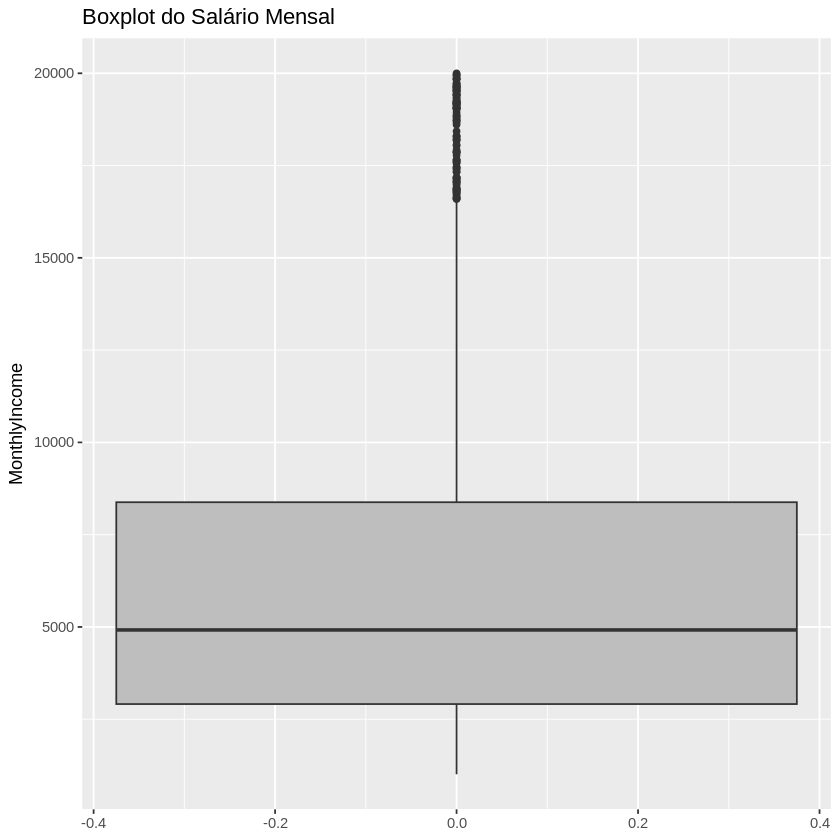

In [ ]:
ggplot(Df, aes(y = MonthlyIncome)) +
  geom_boxplot(fill = "gray") +
  labs(title = "Boxplot do Salário Mensal")

a média (6 503) é maior que a mediana (4 919) - a maioria dos funcionários ganha salários relativamente baixos mas temos mtos outliers (salários mto acima do padrão) - não ha outliers em baixo. Estrutura salarial em pirâmide

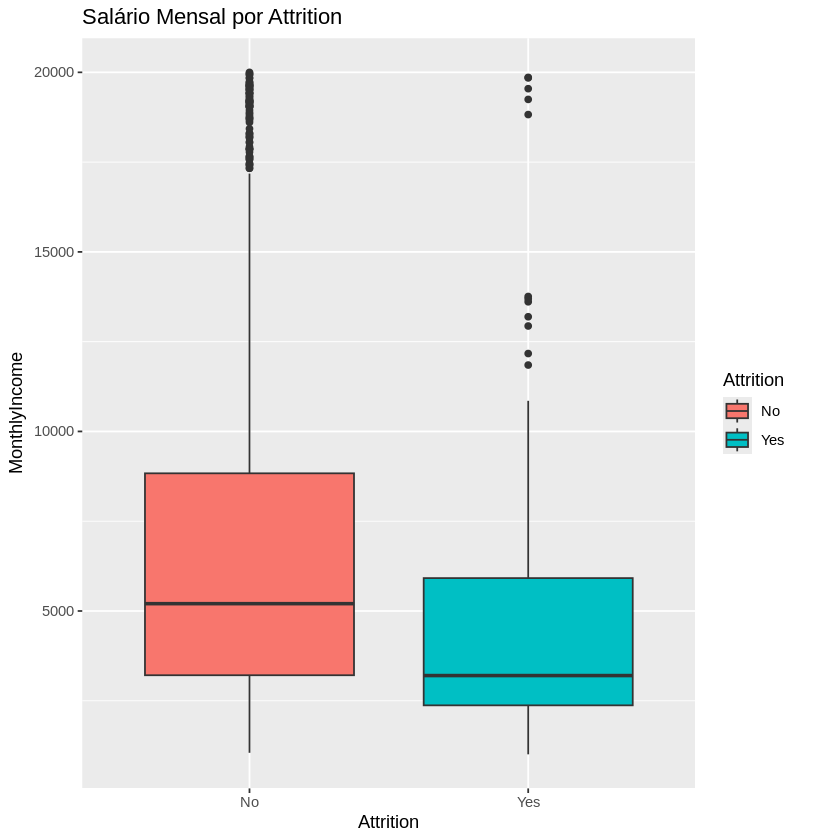

In [ ]:
ggplot(Df, aes(x = Attrition, y = MonthlyIncome, fill = Attrition)) +
  geom_boxplot() +
  labs(title = "Salário Mensal por Attrition")

salário baixo associado a quem quer sair (mediana do yes bem + baixa que a do no); a caixa do no é maior que a do yes: maior variedade salarial entre quem não quer sair ; o bigode superior da caixa no é bem maior e tem mtos outliers (funcionários mto bem pagos e não querem sair) - quem quer sair da IBM tende a ganhar significativamente menos do que quem quer ficar e  estão em escalões salariais + baixos. Possíveis problemas? o tamanho da amostra não é o mesmo (no summary vemos que o no tem 1233 pessoas e yes 237)

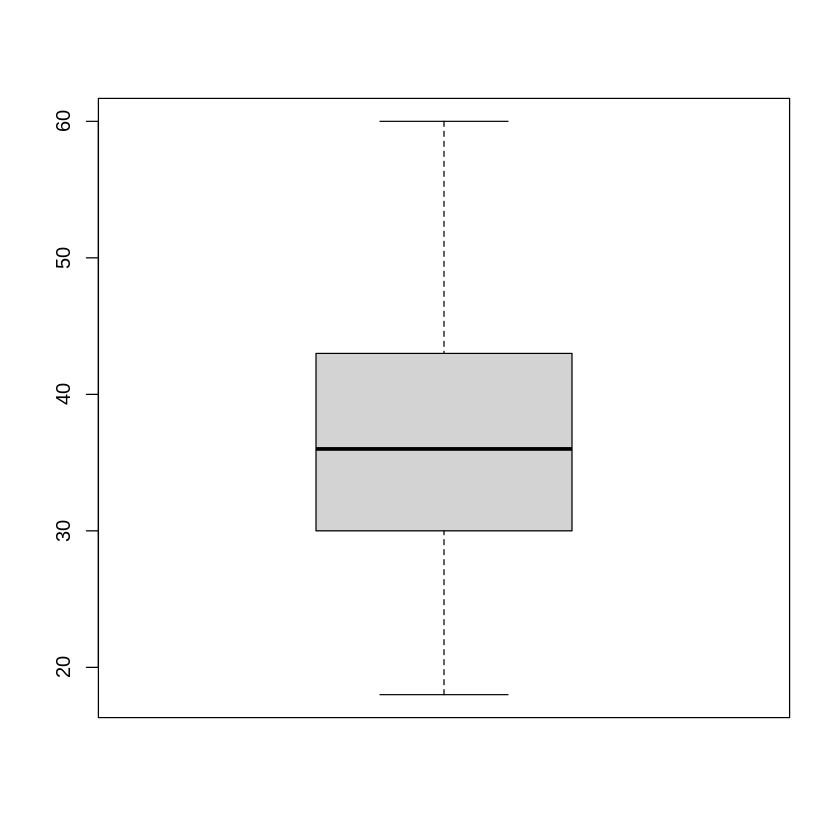

In [ ]:
boxplot(Df$Age)

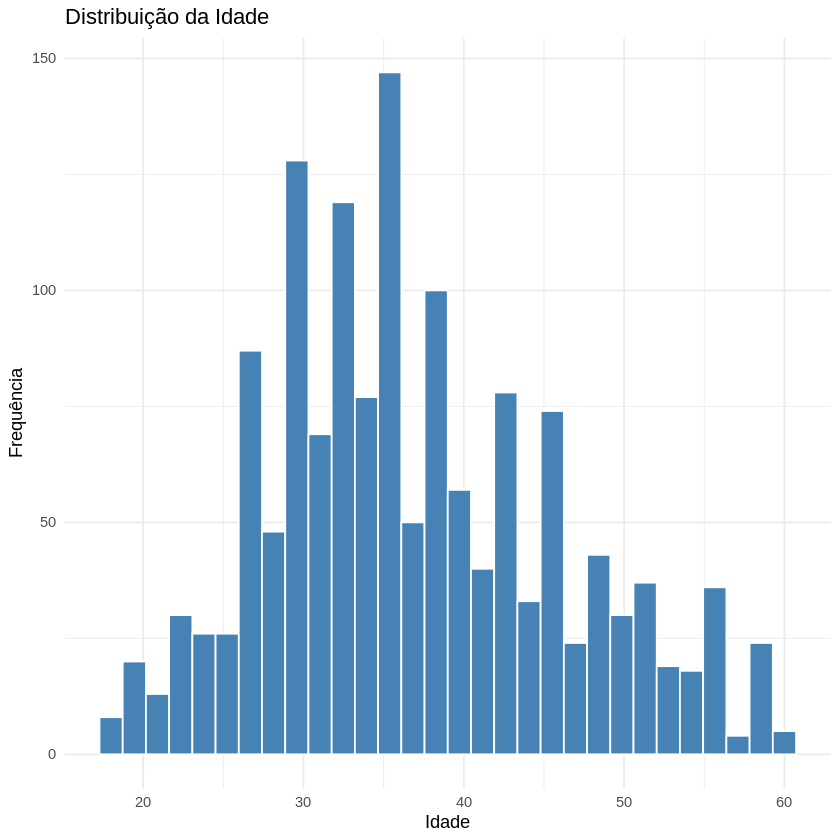

In [ ]:
ggplot(Df, aes(x = Age)) +
  geom_histogram(bins = 30, fill = "steelblue", color = "white") +
  labs(title = "Distribuição da Idade", x = "Idade", y = "Frequência") +
  theme_minimal()

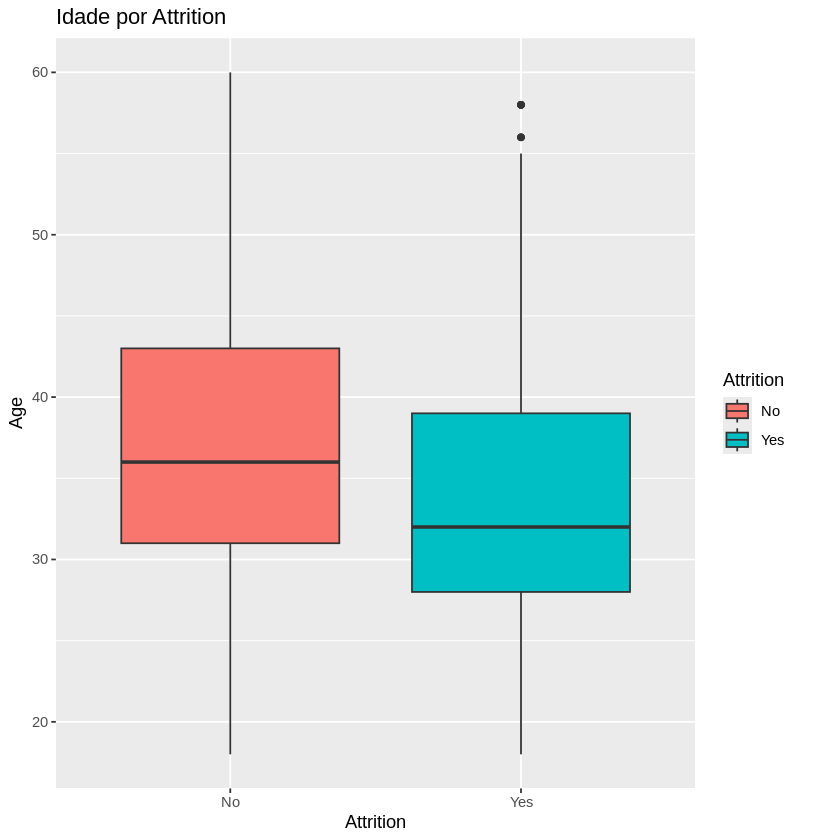

In [ ]:
ggplot(Df, aes(x = Attrition, y = Age, fill = Attrition)) +
  geom_boxplot() +
  labs(title = "Idade por Attrition")

mediana do yes + baixa
caixa no maior o que indica maior variedade etária que quem quer sair
bigode do no maior - não há pessoas perto dos 60 a querer sair e quem quer sair é + jovem

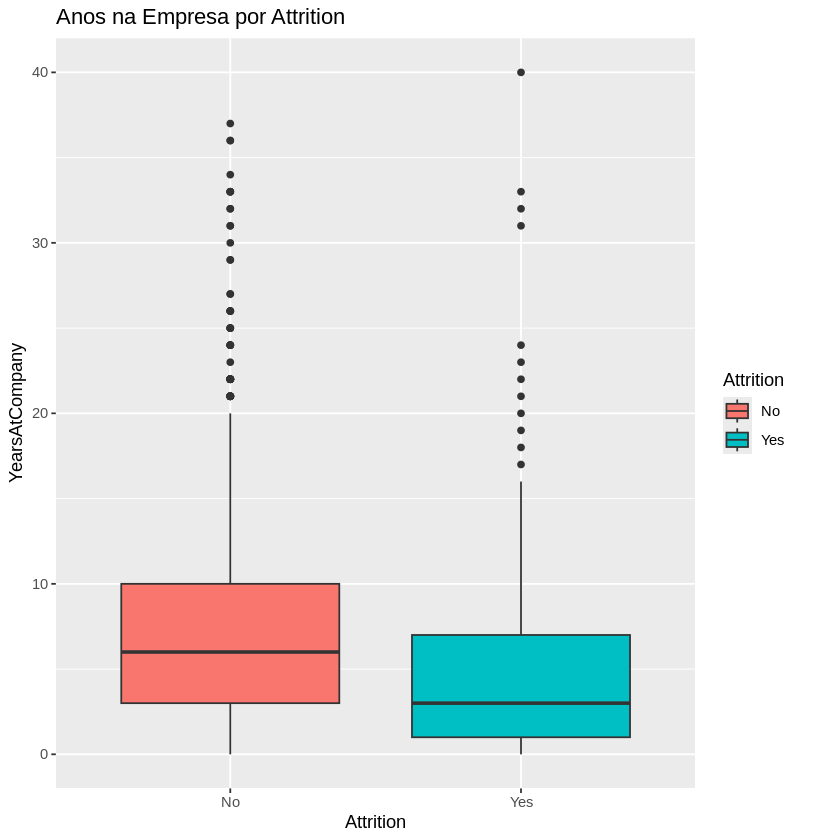

In [ ]:
ggplot(Df, aes(x = Attrition, y = YearsAtCompany, fill = Attrition)) +
  geom_boxplot() +
  labs(title = "Anos na Empresa por Attrition")

"no" tem mediana mais alta - mais anos na empresa não querem sair > o tempo na empresa está associado a uma retenção maior;
mtos outliers  

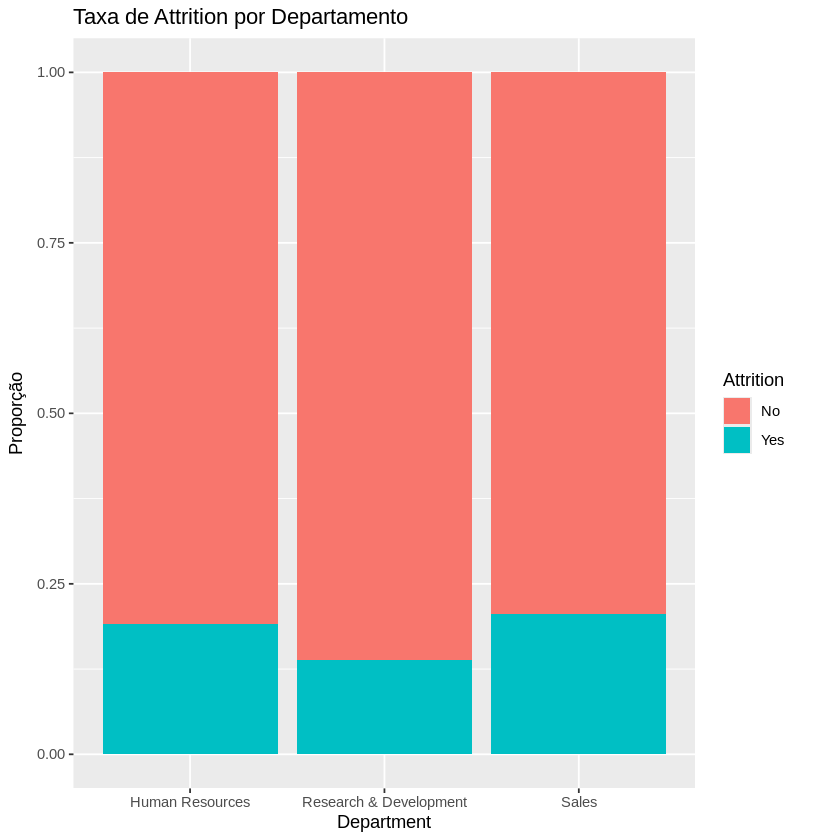

In [ ]:
ggplot(Df, aes(x = Department, fill = Attrition)) +
geom_bar(position = "fill") +
labs(title = "Taxa de Attrition por Departamento", y = "Proporção")

- position fill é o que faz com que as barras tenham o mesmo tamanho
- sales tem attrition maior logo de seguida Human Resources (HR tem poucos colaboradores)

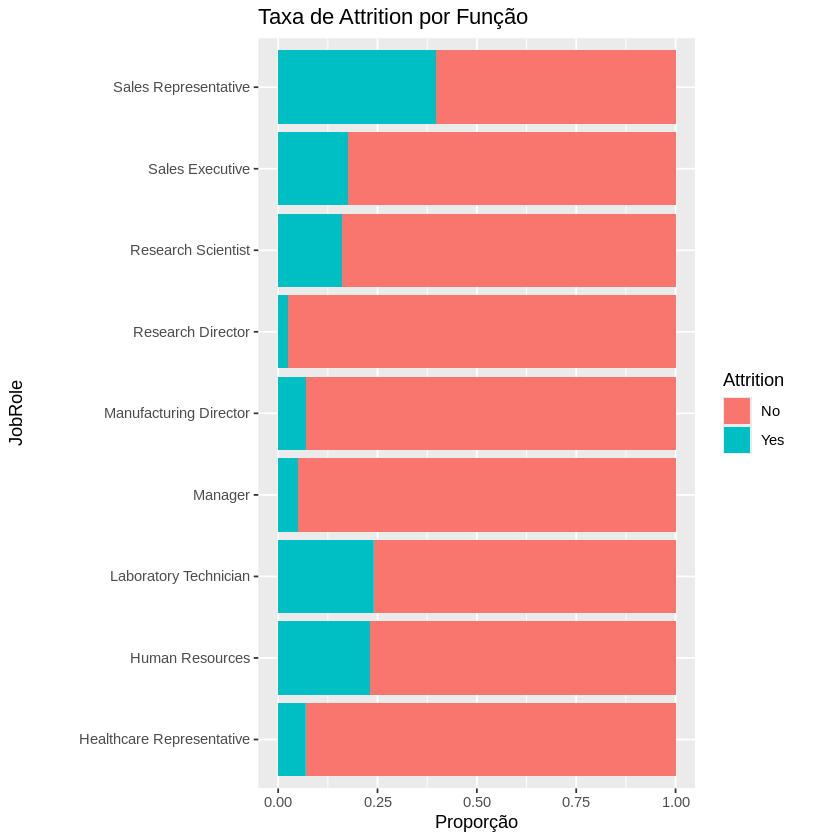

In [ ]:
ggplot(Df, aes(x = JobRole, fill = Attrition)) +
  geom_bar(position = "fill") +
  coord_flip() +
  labs(title = "Taxa de Attrition por Função", y = "Proporção")

- sales representative com a maior taxa de attrition (função mais problemática)
- seguida por laboratory technician e HR
- podemos comparar este gráfico com o anterior (dentro das sales os SR querem sair mais)
- manager e RD têm baixo attririon (melhores salários?)

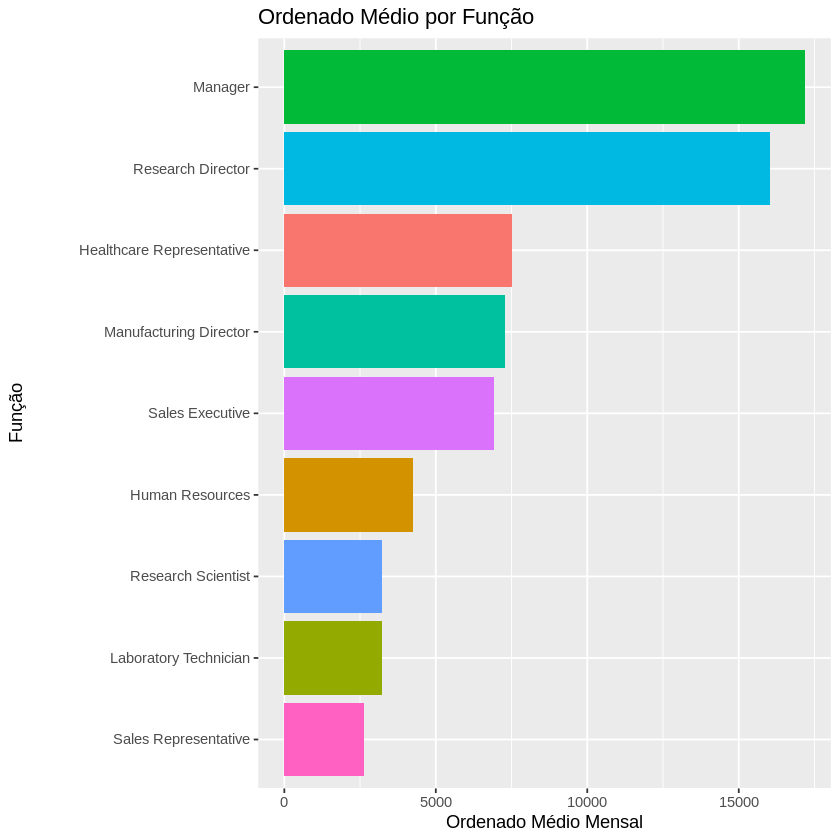

In [ ]:
ggplot(Df, aes(x = reorder(JobRole, MonthlyIncome, FUN = mean),
               y = MonthlyIncome,
               fill = JobRole)) +
  stat_summary(fun = mean, geom = "bar", show.legend = FALSE) +
  coord_flip() +
  labs(title = "Ordenado Médio por Função",
       x = "Função",
       y = "Ordenado Médio Mensal")

In [ ]:
ordenado mostra a vontade sair

ERROR: Error in parse(text = input): <text>:1:10: unexpected symbol
1: ordenado mostra
             ^


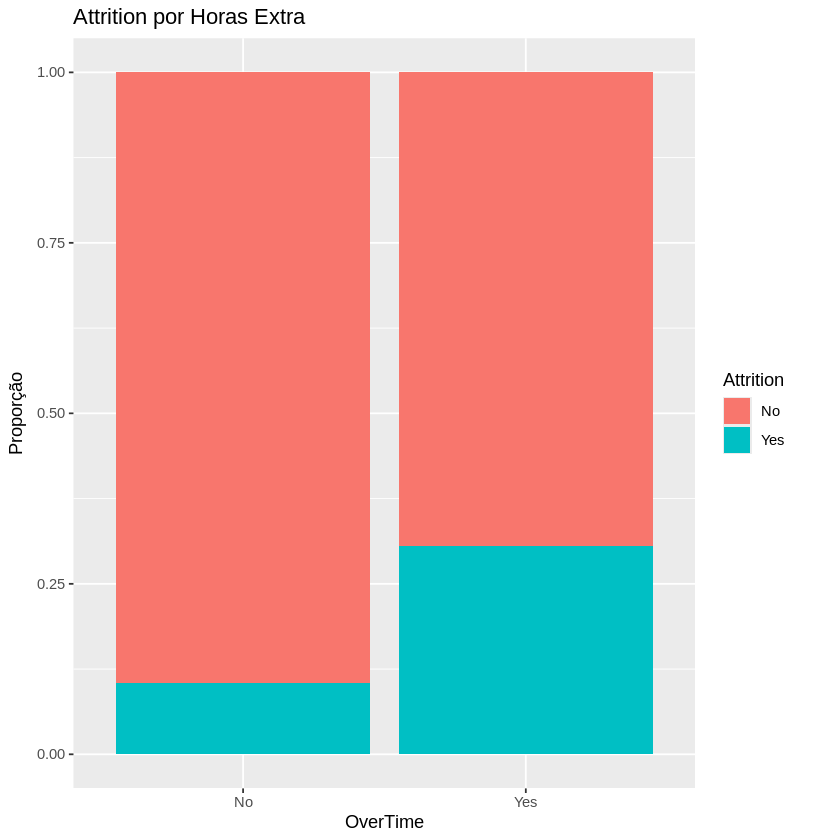

In [ ]:
ggplot(Df, aes(x = OverTime, fill = Attrition)) +
  geom_bar(position = "fill") +
  labs(title = "Attrition por Horas Extra", y = "Proporção")

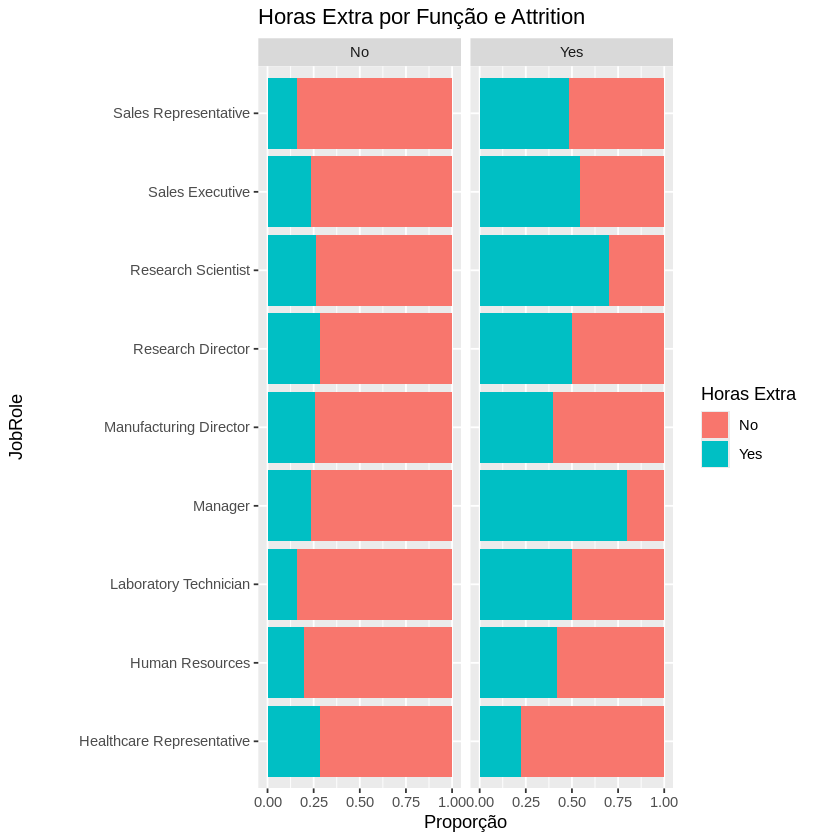

In [ ]:
ggplot(Df, aes(x = JobRole, fill = OverTime)) +
  geom_bar(position = "fill") +
  coord_flip() +
  facet_wrap(~ Attrition) +
  labs(title = "Horas Extra por Função e Attrition",
       y = "Proporção",
       fill = "Horas Extra")

- "Yes" a proporção de pessoas que fazem horas extra é muito maior do que no "No", transversalmente a quase todas as funções - fazer horas extra praticamente duplica a vontade de querer sair
- As funções com maior attrition: SR, Laboratory Technician e HR, são também as que combinam salários mais baixos, menor satisfação no trabalho e maior incidência de horas extra. Dentro de cada função, quem sai tende a ganhar menos e a fazer mais horas extra do que quem fica. Isto sugere que a rotatividade não é uma característica intrínseca da função, mas o resultado de uma combinação de fatores (sobretudo compensação e sobrecarga de trabalho)

**E agora o Género?**



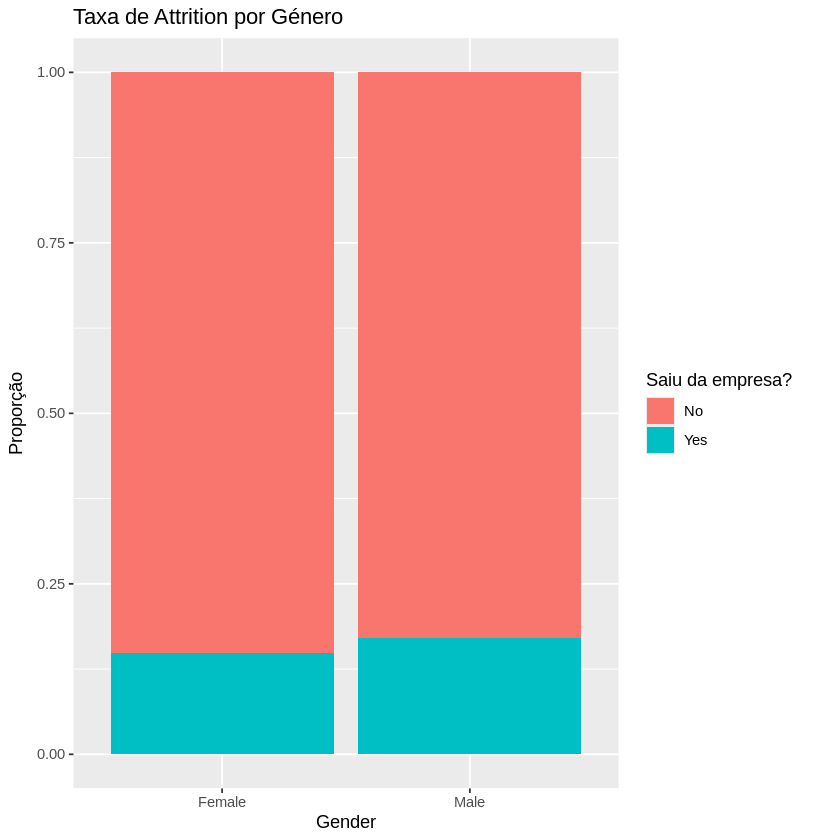

In [ ]:
ggplot(Df, aes(x = Gender, fill = Attrition)) +
  geom_bar(position = "fill") +
   labs(title = "Taxa de Attrition por Género",
       y = "Proporção",
       fill = "Saiu da empresa?")

- taxas semelhantes (homens ligeiramente superiores)

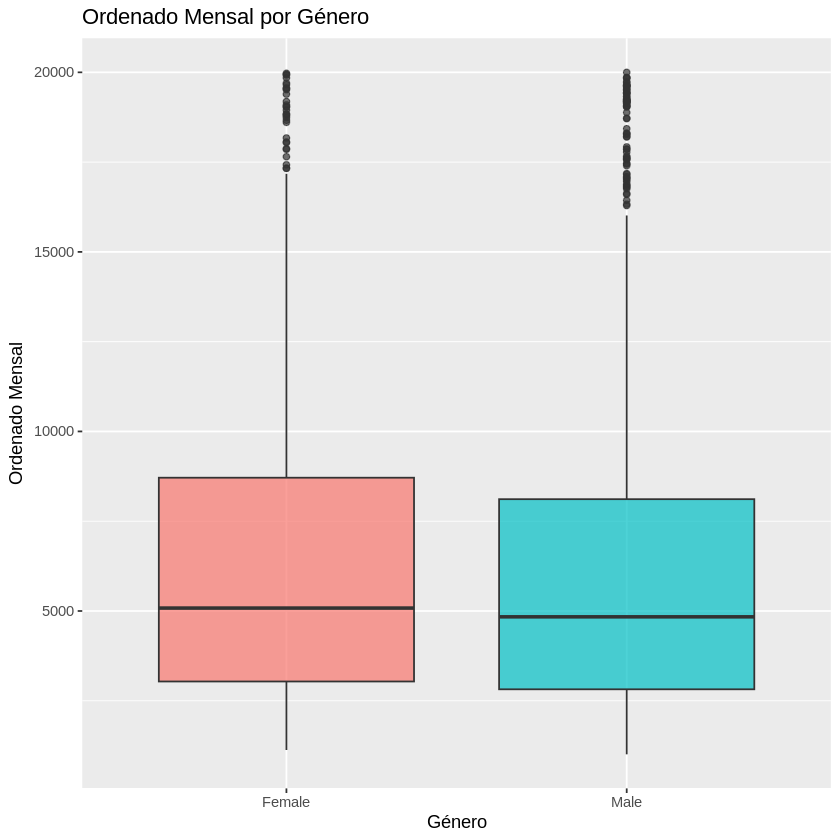

In [ ]:
ggplot(Df, aes(x = Gender, y = MonthlyIncome, fill = Gender)) +
  geom_boxplot(alpha = 0.7, show.legend = FALSE) +
  labs(title = "Ordenado Mensal por Género",
       x = "Género",
       y = "Ordenado Mensal")

- as mulheres têm uma mediana salarial ligeiramente superior à dos homens (diferente da realidade do mercado de trabalho)

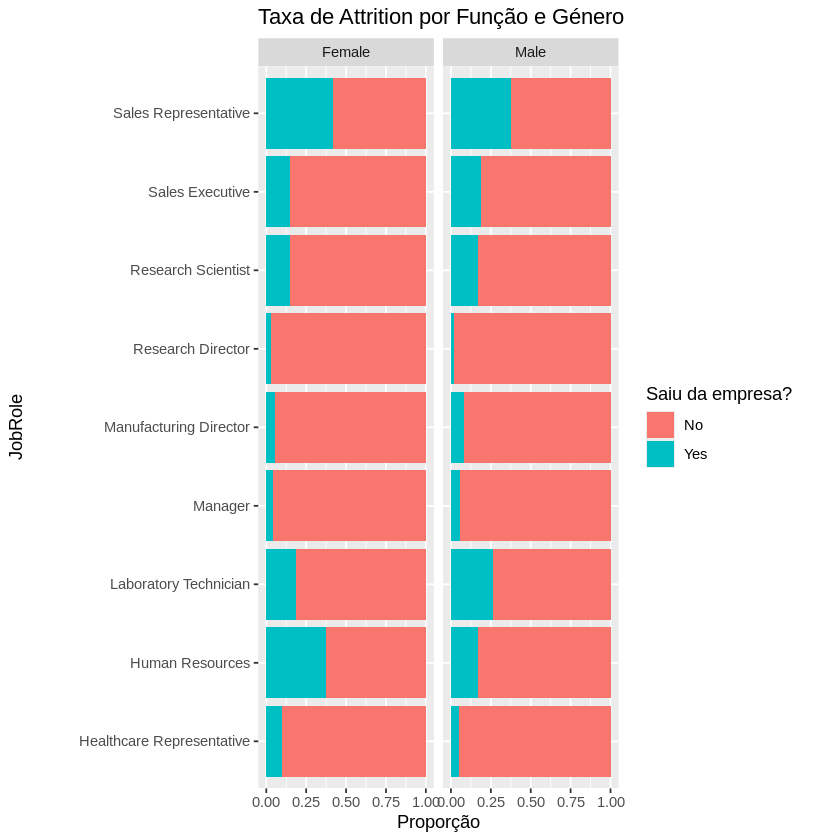

In [ ]:
ggplot(Df, aes(x = JobRole, fill = Attrition)) +
  geom_bar(position = "fill") +
  coord_flip() +
  facet_wrap(~ Gender) +
  labs(title = "Taxa de Attrition por Função e Género",
       y = "Proporção",
       fill = "Saiu da empresa?")

-o género não é um fator determinante

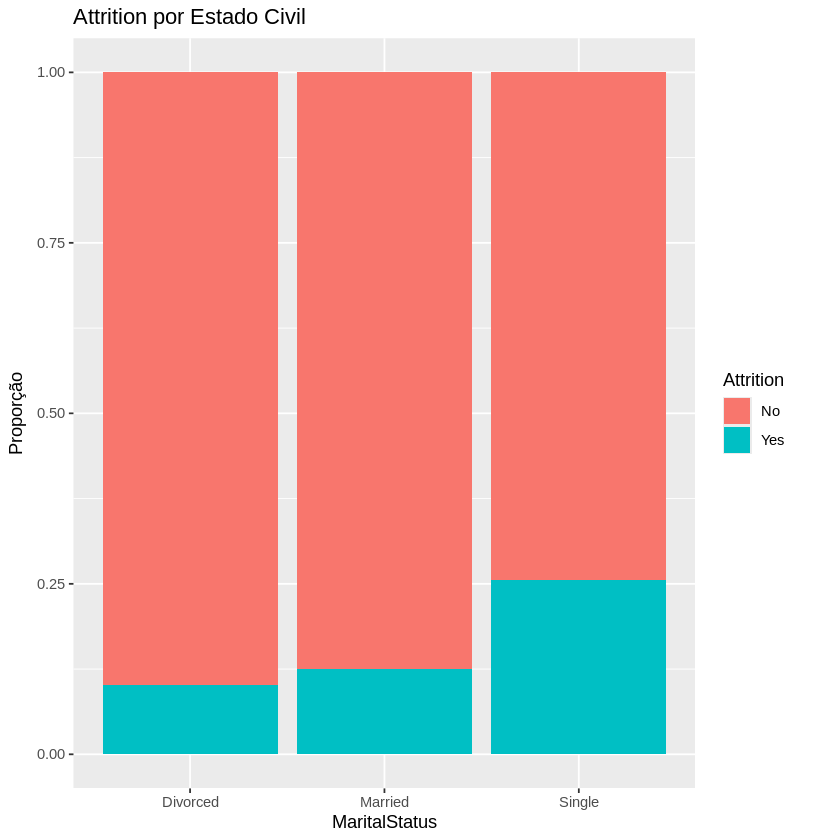

In [ ]:
ggplot(Df, aes(x = MaritalStatus, fill = Attrition)) +
  geom_bar(position = "fill") +
 labs(title = "Attrition por Estado Civil", y = "Proporção")

- singles querem sair mais do que casados e divorciados

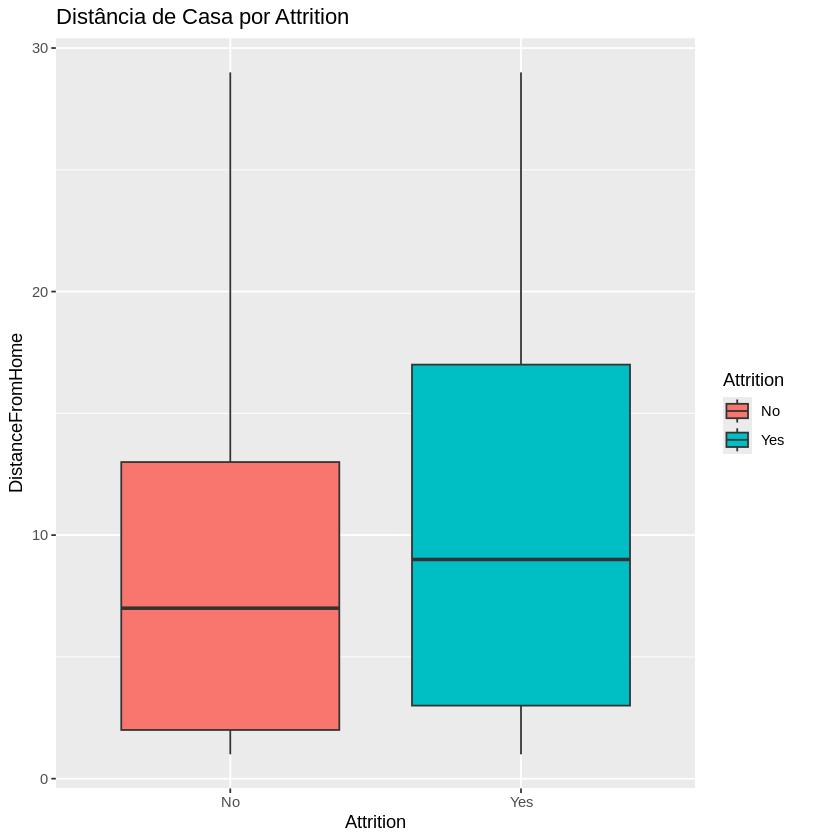

In [ ]:
ggplot(Df, aes(x = Attrition, y = DistanceFromHome, fill = Attrition)) +
  geom_boxplot() +
  labs(title = "Distância de Casa por Attrition")


- yes mediana ligeiramente superior e caixa tb mais alta (maior dispersão o que significa que vivem mais longe)
- quem vive mais longe tende a querer sair da empresa

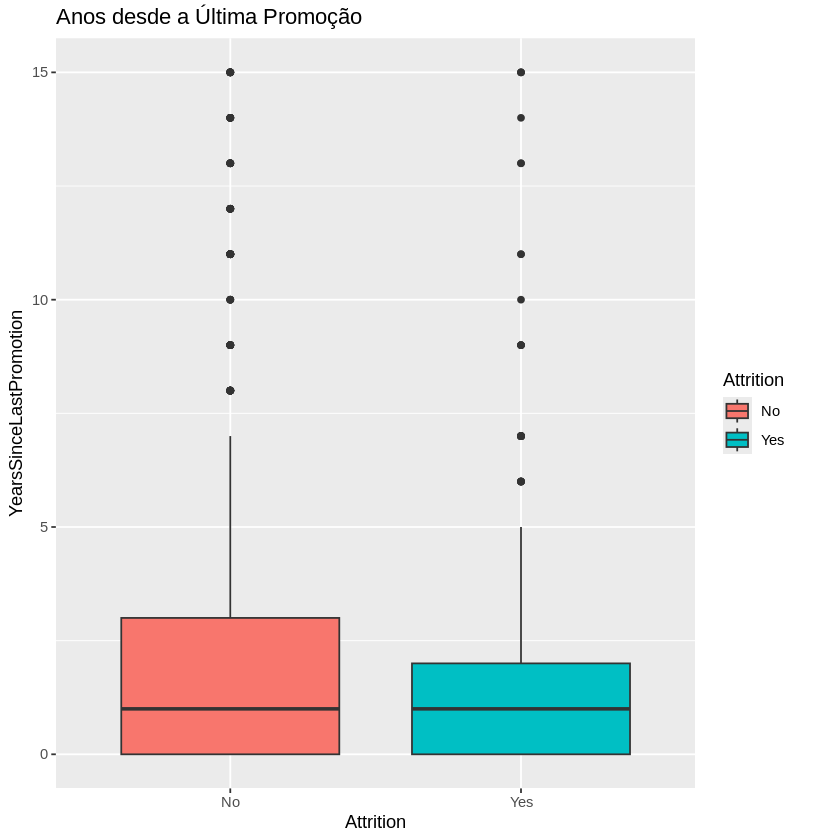

In [ ]:
ggplot(Df, aes(x = Attrition, y = YearsSinceLastPromotion, fill = Attrition)) +
  geom_boxplot() +
  labs(title = "Anos desde a Última Promoção")

- é muito assimétrica à direita (a maiorio dos colabores foi promovido recentemente mas há várias pessoas sem promoção há vários anos até 15 anos)
- medianas baixas e semelhantes ,caixas perto do zero

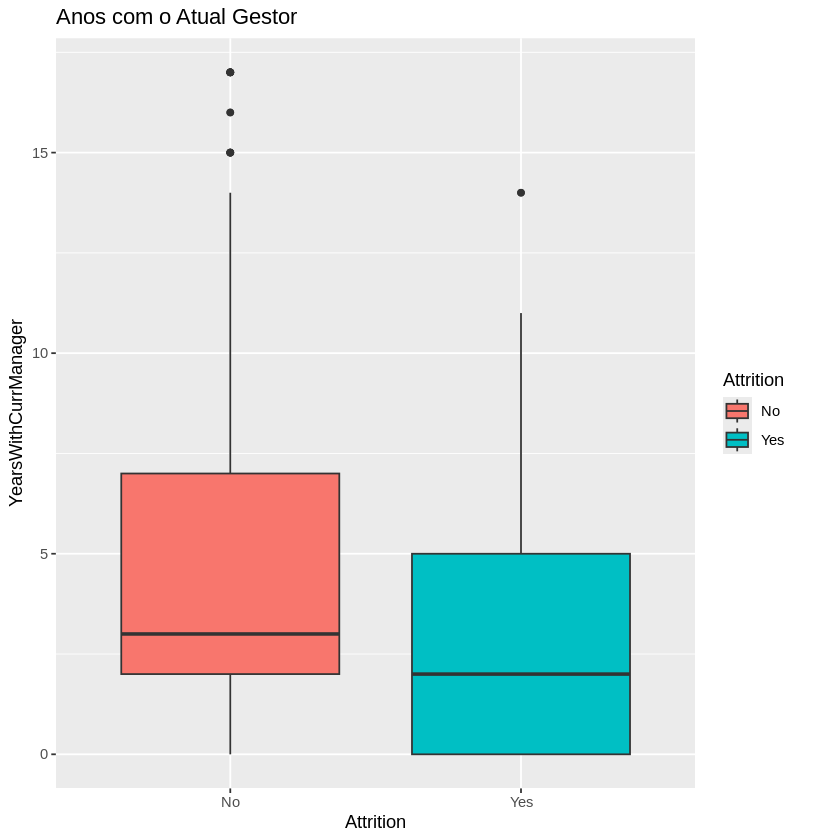

In [ ]:
ggplot(Df, aes(x = Attrition, y = YearsWithCurrManager, fill = Attrition)) +
  geom_boxplot() +
  labs(title = "Anos com o Atual Gestor")

- colaboradores que querem sair tendem a ter menos anos com o gestor atual do que os que ficaram (relação gestor-colaborador imatura devido a pouco tempo ou mudança recente de gestor pode ter desencadeado insatisfação e levado a saída)

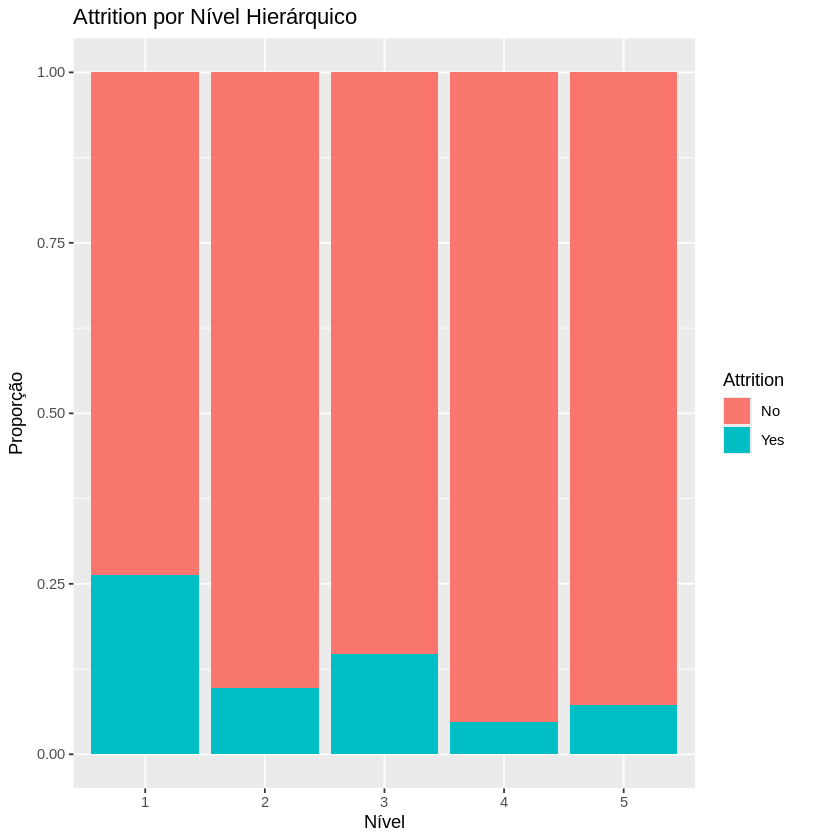

In [ ]:
ggplot(Df, aes(x = factor(JobLevel), fill = Attrition)) +
  geom_bar(position = "fill") +
  labs(title = "Attrition por Nível Hierárquico", x = "Nível", y = "Proporção")

- o nivel 1 é o que tem o yes mais elevado (tipicamente + jovens com - vinculo a empresa, salarios + baixos)
- nível 2 taxa desce drasticamente (estabiliza) -> proporções!

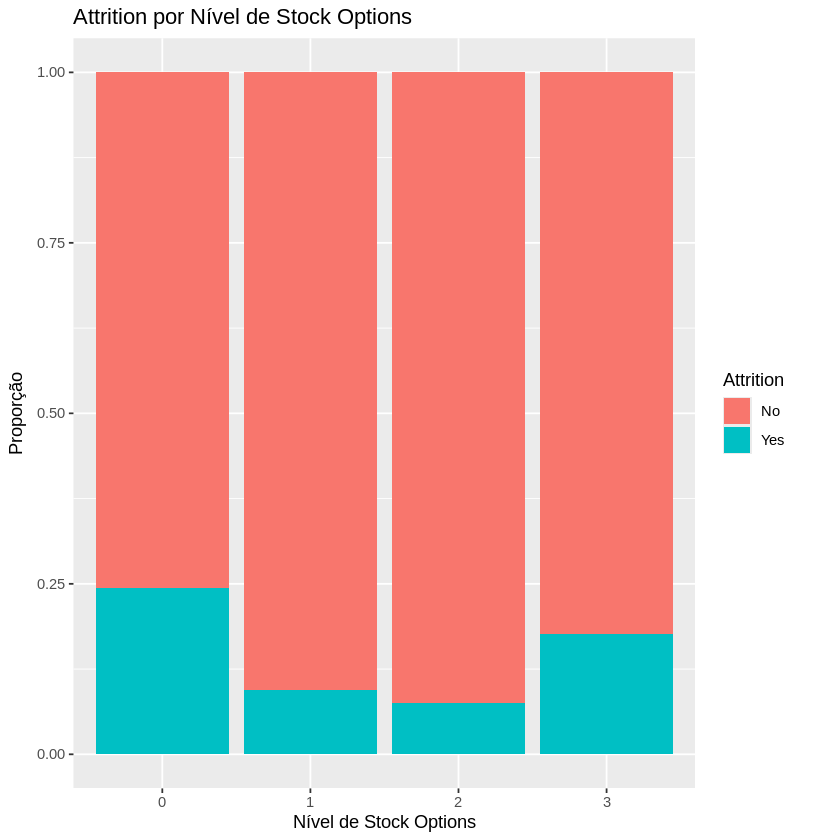

In [ ]:
ggplot(Df, aes(x = factor(StockOptionLevel), fill = Attrition)) +
  geom_bar(position = "fill") +
  labs(title = "Attrition por Nível de Stock Options",
       x = "Nível de Stock Options", y = "Proporção")

- nivel o com maior atrittion (não há incentivo financeiro)
- nivel 3 aumento no attrition! (apenas tem 85 colabores por isso é + sensivel a flutuações)

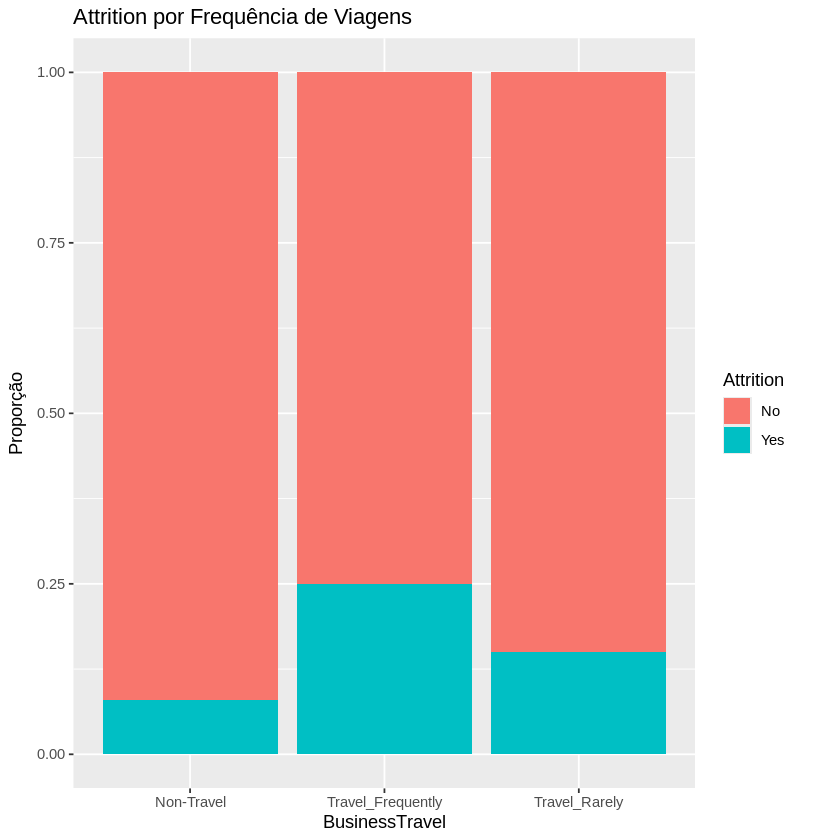

In [ ]:
ggplot(Df, aes(x = BusinessTravel, fill = Attrition)) +
  geom_bar(position = "fill") +
  labs(title = "Attrition por Frequência de Viagens", y = "Proporção")


- quem viaja frequentemente tem uma taxa de saida maior (desgaste físico, familia, maior exposição ao mercado externo)

**Satisfação**

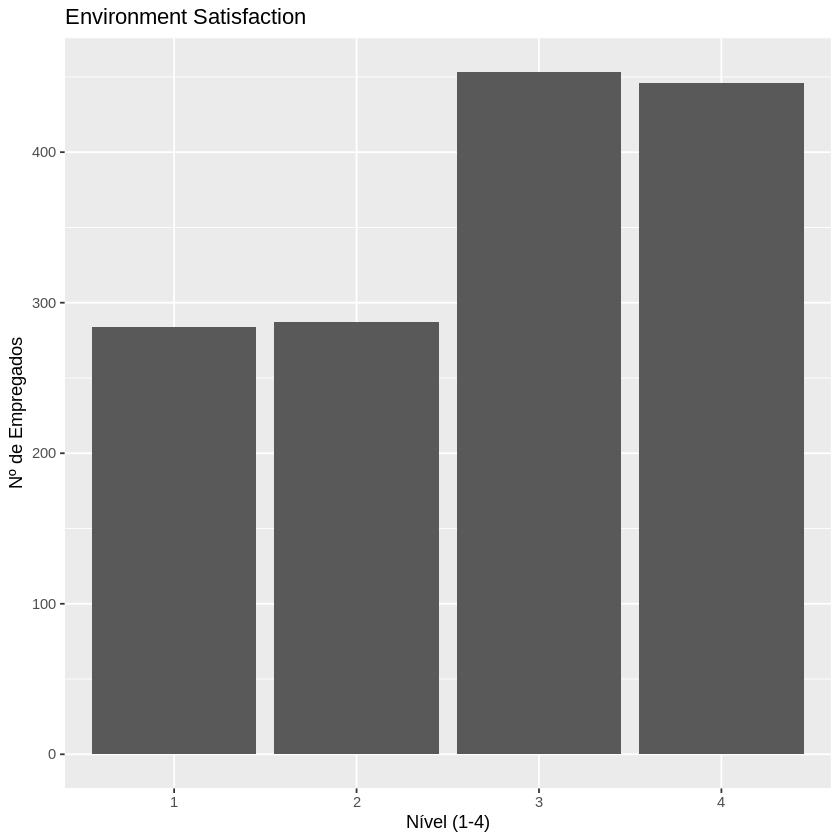

In [ ]:
ggplot(Df, aes(x = factor(EnvironmentSatisfaction))) +
  geom_bar() +
  labs(title = "Environment Satisfaction", x = "Nível (1-4)", y = "Nº de Empregados")

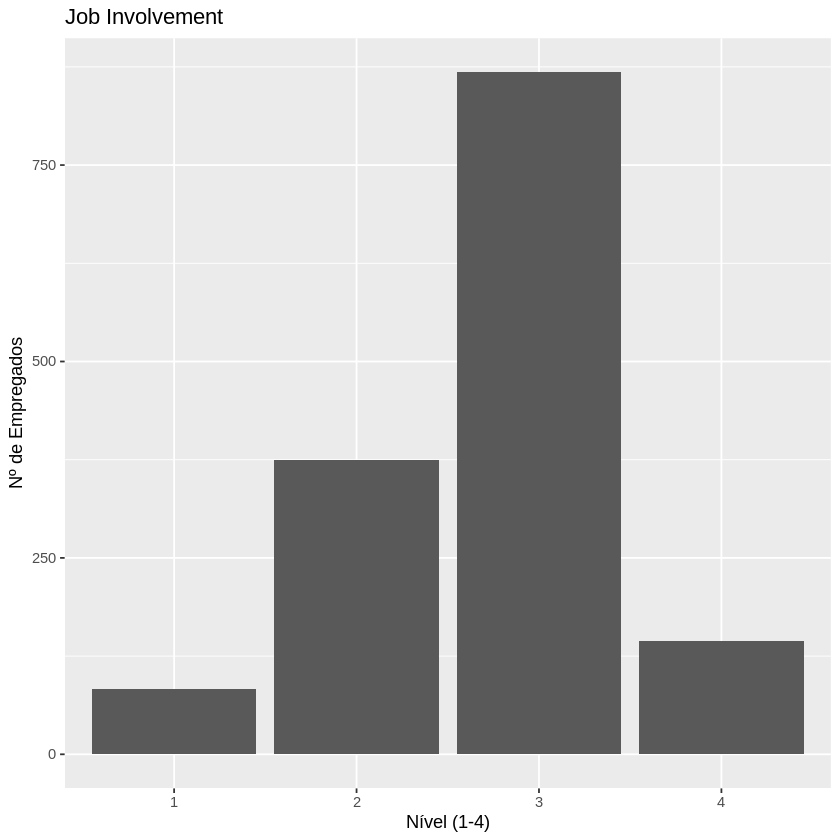

In [ ]:
ggplot(Df, aes(x = factor(JobInvolvement))) +
  geom_bar() +
  labs(title = "Job Involvement", x = "Nível (1-4)", y = "Nº de Empregados")

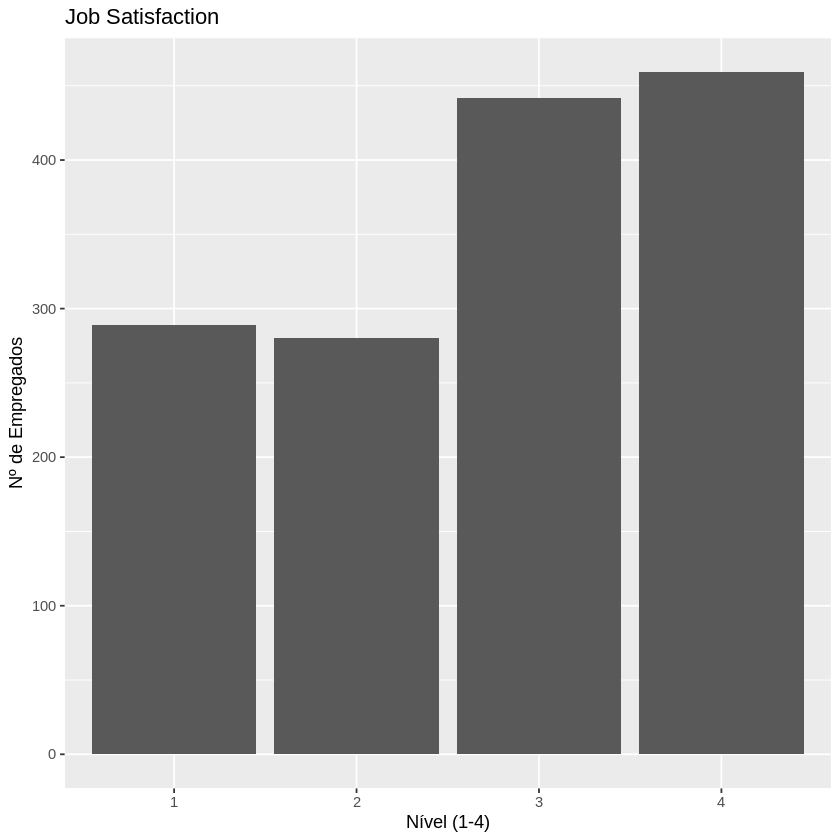

In [ ]:
ggplot(Df, aes(x = factor(JobSatisfaction))) +
  geom_bar() +
  labs(title = "Job Satisfaction", x = "Nível (1-4)", y = "Nº de Empregados")

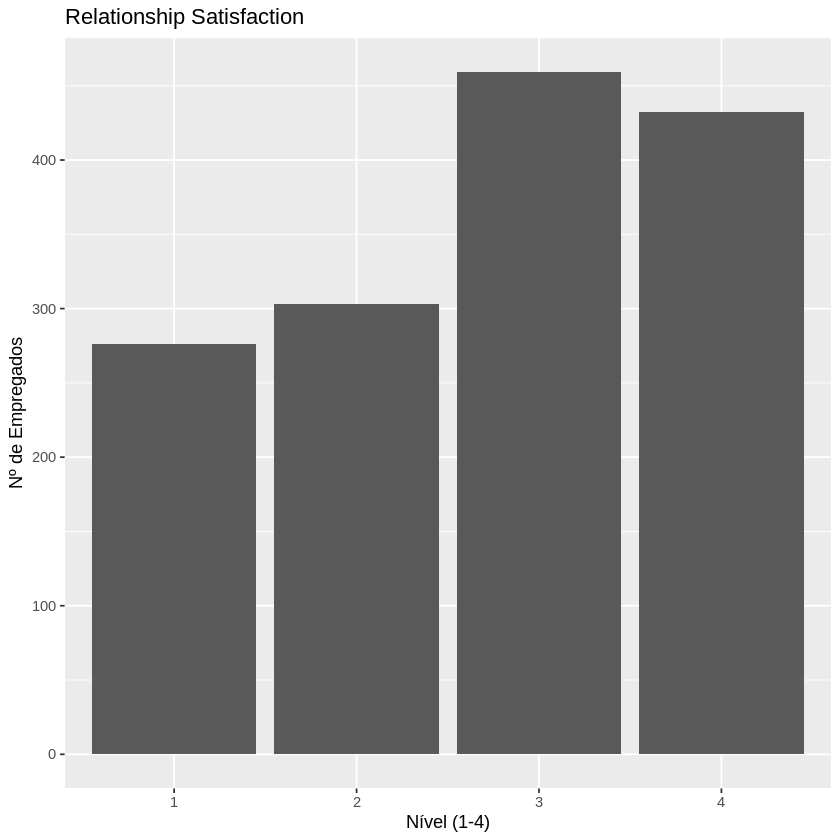

In [ ]:
ggplot(Df, aes(x = factor(RelationshipSatisfaction))) +
  geom_bar() +
  labs(title = "Relationship Satisfaction", x = "Nível (1-4)", y = "Nº de Empregados")

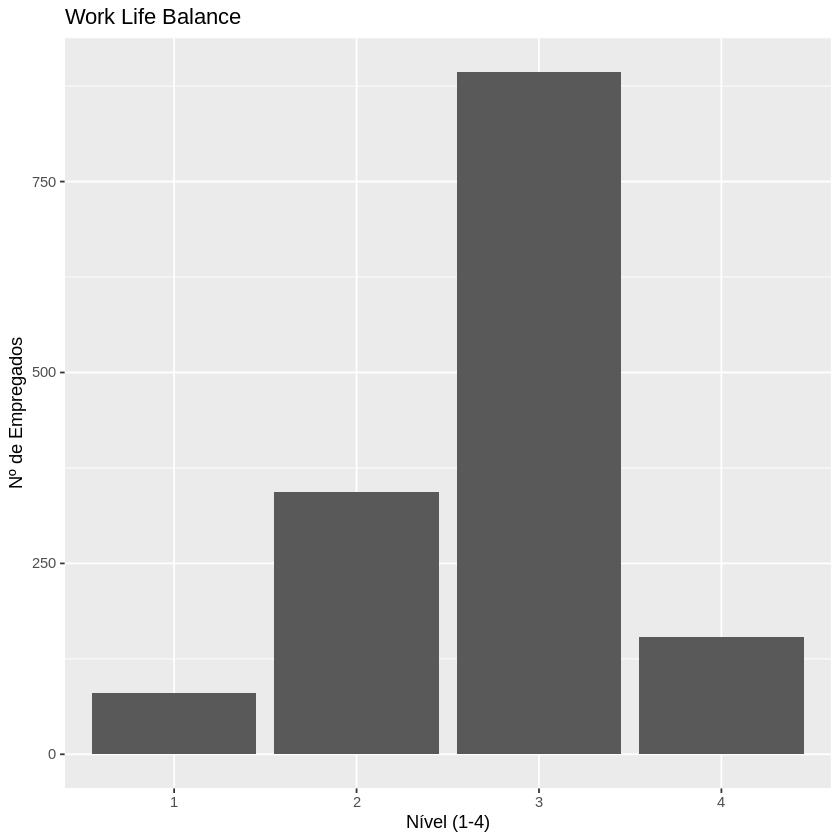

In [ ]:
ggplot(Df, aes(x = factor(WorkLifeBalance))) +
  geom_bar() +
  labs(title = "Work Life Balance", x = "Nível (1-4)", y = "Nº de Empregados")

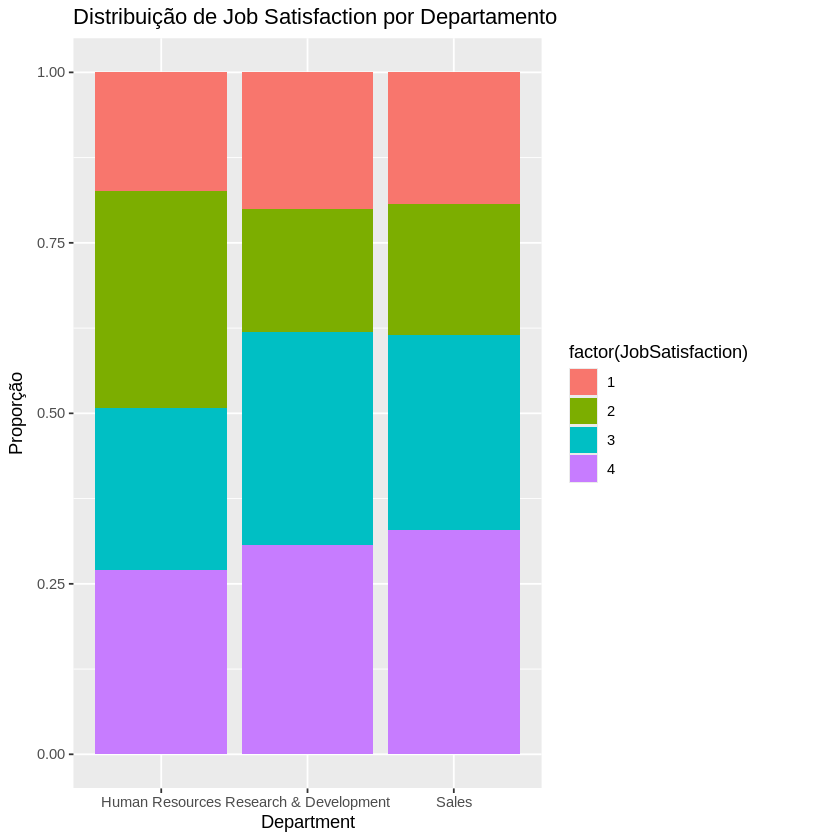

In [ ]:
ggplot(Df, aes(x = Department, fill = factor(JobSatisfaction))) +
  geom_bar(position = "fill") +
  labs(title = "Distribuição de Job Satisfaction por Departamento", y = "Proporção")

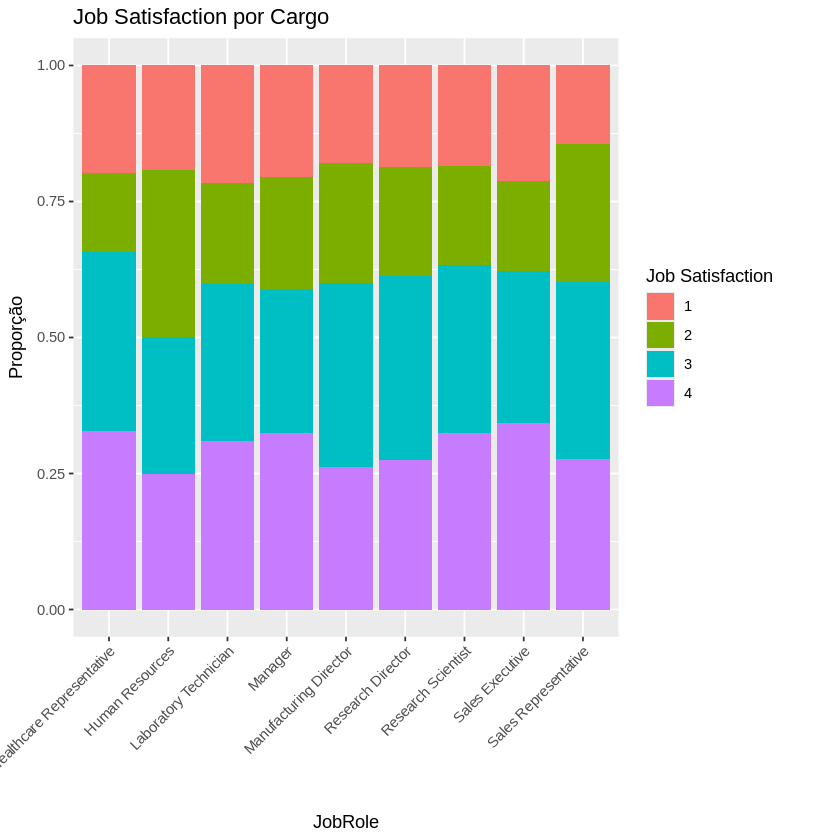

In [ ]:
ggplot(Df, aes(x = JobRole, fill = factor(JobSatisfaction))) +
  geom_bar(position = "fill") +
  labs(title = "Job Satisfaction por Cargo", y = "Proporção", fill = "Job Satisfaction") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

HR apenas 25%  no nivel 4

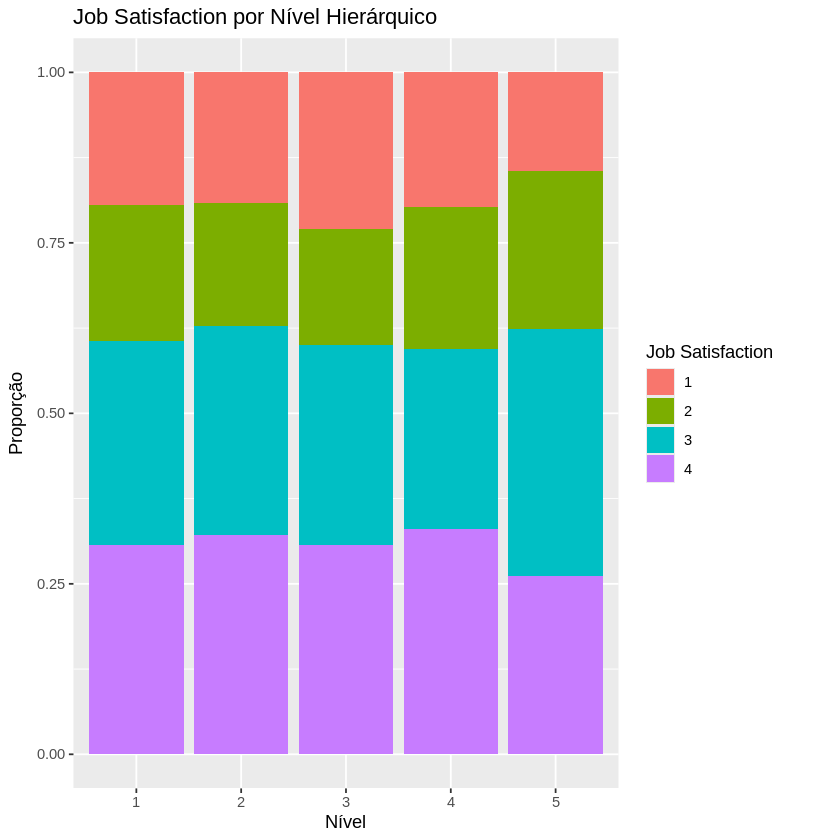

In [ ]:
ggplot(Df, aes(x = factor(JobLevel), fill = factor(JobSatisfaction))) +
  geom_bar(position = "fill") +
  labs(title = "Job Satisfaction por Nível Hierárquico", x = "Nível", y = "Proporção", fill = "Job Satisfaction")

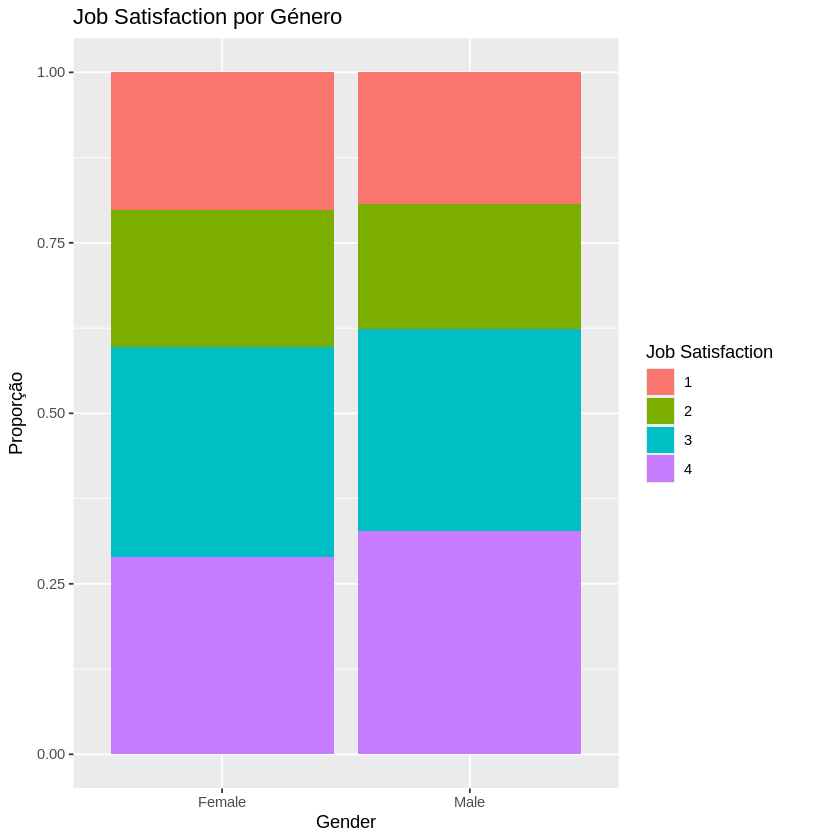

In [ ]:
ggplot(Df, aes(x = Gender, fill = factor(JobSatisfaction))) +
  geom_bar(position = "fill") +
  labs(title = "Job Satisfaction por Género", y = "Proporção", fill = "Job Satisfaction")

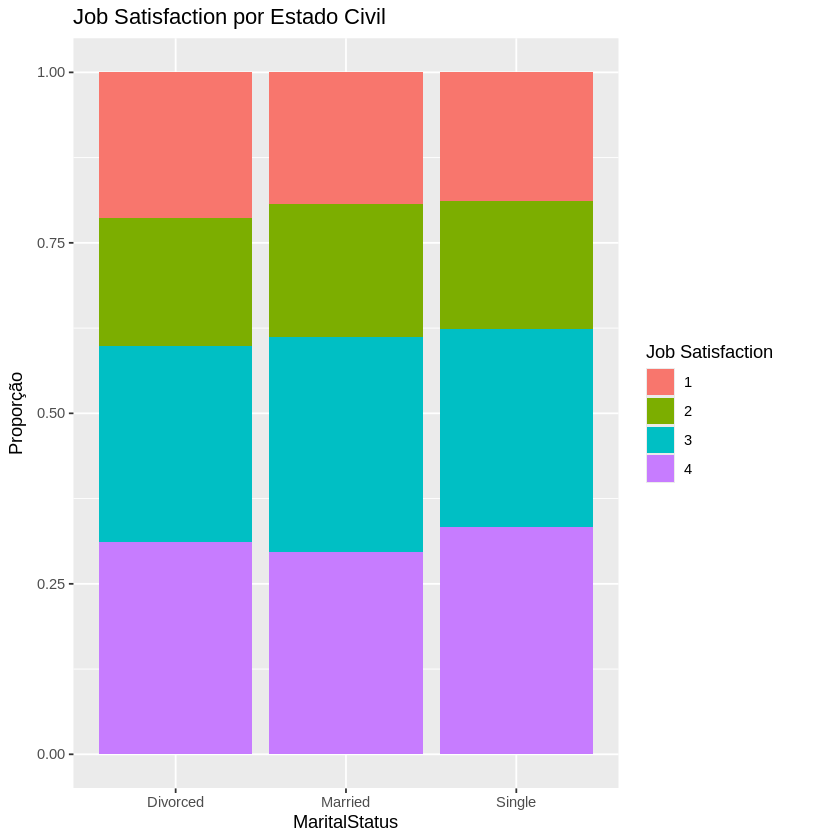

In [ ]:
ggplot(Df, aes(x = MaritalStatus, fill = factor(JobSatisfaction))) +
  geom_bar(position = "fill") +
  labs(title = "Job Satisfaction por Estado Civil", y = "Proporção", fill = "Job Satisfaction")

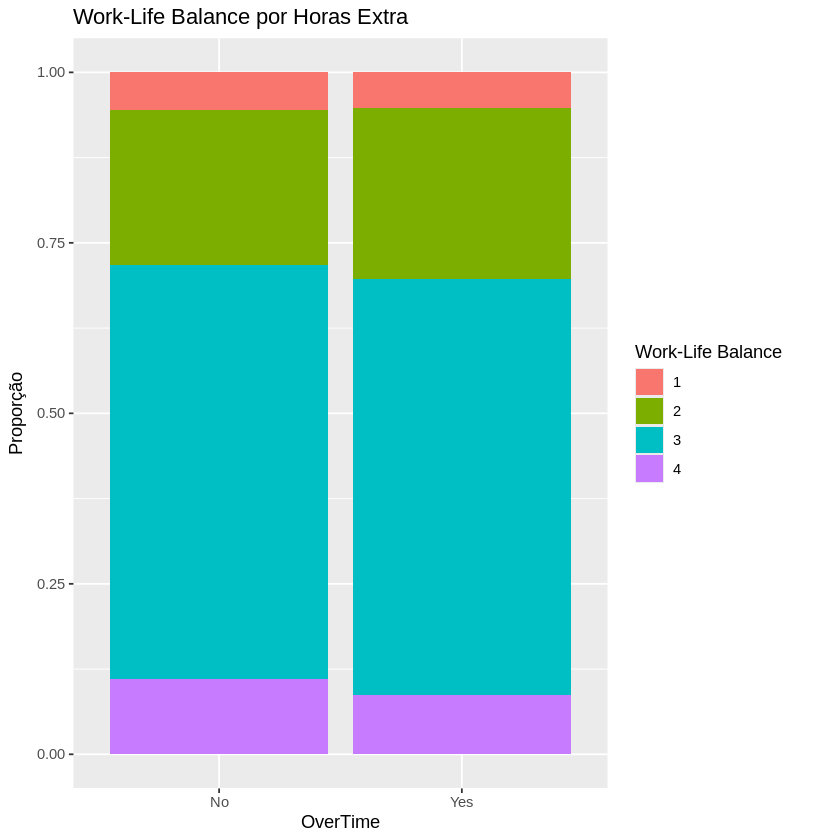

In [ ]:
ggplot(Df, aes(x = OverTime, fill = factor(WorkLifeBalance))) +
  geom_bar(position = "fill") +
  labs(title = "Work-Life Balance por Horas Extra", y = "Proporção", fill = "Work-Life Balance")

OverTime vs Work-Life Balance: praticamente nenhuma diferença entre quem faz horas extra e quem não faz

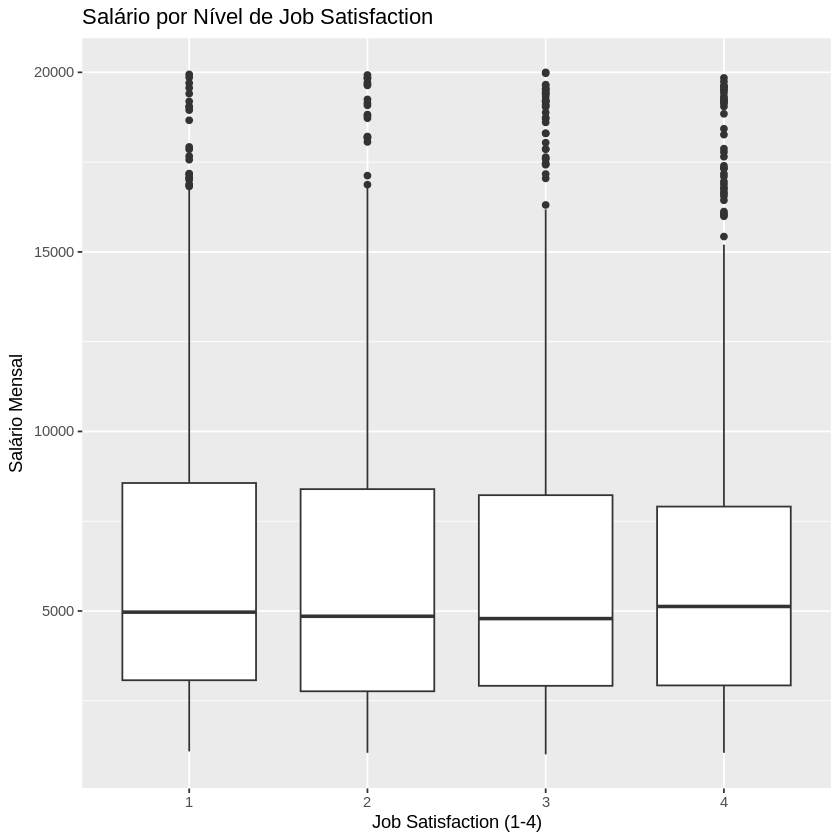

In [ ]:
ggplot(Df, aes(x = factor(JobSatisfaction), y = MonthlyIncome)) +
  geom_boxplot() +
  labs(title = "Salário por Nível de Job Satisfaction", x = "Job Satisfaction (1-4)", y = "Salário Mensal")

Salário vs Job Satisfaction: as proporções são identicas, sem tendência clara - não há evidência de que ganhar mais torne alguém mais satisfeito no trabalho


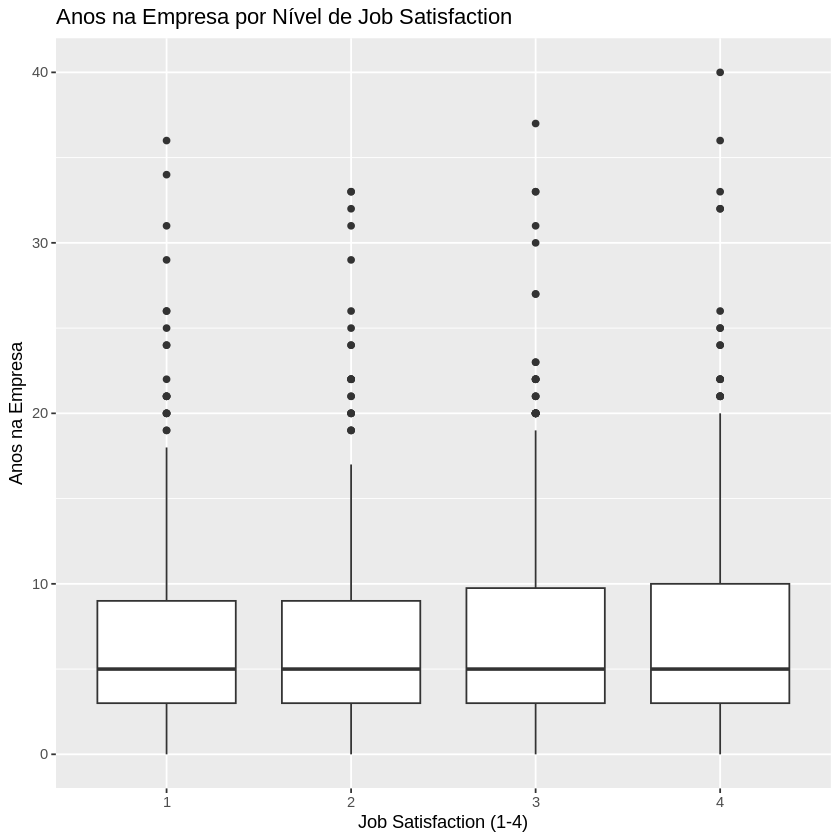

In [ ]:
ggplot(Df, aes(x = factor(JobSatisfaction), y = YearsAtCompany)) +
  geom_boxplot() +
  labs(title = "Anos na Empresa por Nível de Job Satisfaction", x = "Job Satisfaction (1-4)", y = "Anos na Empresa")

Antiguidade vs Job Satisfaction: o mesmo padrão — médias praticamente iguais (todas à volta de 7.0 anos, mediana 5.0 em todos os níveis). A satisfação não parece estar relacionada com há quanto tempo a pessoa está na empresa.